# 03 · Patient Segmentation
### K-Means clustering for operational analysis

**Dataset:** patient-level appointment history derived from `data/appointments.csv`.

**Goal:** group patients into operationally useful segments so the hospital can tailor reminders, care coordination and outreach.

**Features:** age, number of appointments, average booking lead time, chronic-condition count and SMS contact rate.

> No-show rate is **not** used to build the clusters. It is added afterwards as a profiling metric, so the segments describe utilisation and engagement rather than simply sorting patients by outcome.
        

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

%matplotlib inline
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.25})

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "appointments.csv"
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
print("Project root:", ROOT)
print("Using:", DATA_PATH)
        

Project root: C:\Users\Lenovo\health_analytics
Using: C:\Users\Lenovo\health_analytics\data\appointments.csv


## 1. Build one row per patient

In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw[raw["Age"] >= 0].copy()
for column in ["ScheduledDay", "AppointmentDay"]:
    df[column] = pd.to_datetime(df[column]).dt.tz_localize(None)

df["lead_time_days"] = (
    df["AppointmentDay"].dt.normalize() - df["ScheduledDay"].dt.normalize()
).dt.days.clip(lower=0)
df["has_handicap"] = (df["Handcap"] > 0).astype(int)
df["chronic_conditions"] = (
    df["Hipertension"] + df["Diabetes"] + df["Alcoholism"] + df["has_handicap"]
)
df["target"] = (df["No-show"] == "Yes").astype(int)

patients = (
    df.groupby("PatientId")
    .agg(
        age=("Age", "mean"),
        appointments=("AppointmentID", "count"),
        avg_lead_time=("lead_time_days", "mean"),
        chronic_conditions=("chronic_conditions", "mean"),
        sms_rate=("SMS_received", "mean"),
        no_show_rate=("target", "mean"),
    )
    .reset_index()
)

print(f"Patients: {len(patients):,}")
patients[["age", "appointments", "avg_lead_time", "chronic_conditions", "sms_rate", "no_show_rate"]].describe().round(2)
        

Patients: 62,298


,age,appointments,avg_lead_time,chronic_conditions,sms_rate,no_show_rate
count,62298.00,62298.00,62298.00,62298.00,62298.00,62298.00
mean,36.71,1.77,11.16,0.31,0.33,0.20
std,23.53,1.77,15.06,0.62,0.42,0.35
min,0.00,1.00,0.00,0.00,0.00,0.00
25%,17.00,1.00,0.00,0.00,0.00,0.00
50%,36.00,1.00,5.50,0.00,0.00,0.00
75%,56.00,2.00,16.50,0.00,0.67,0.33
max,115.00,88.00,179.00,4.00,1.00,1.00


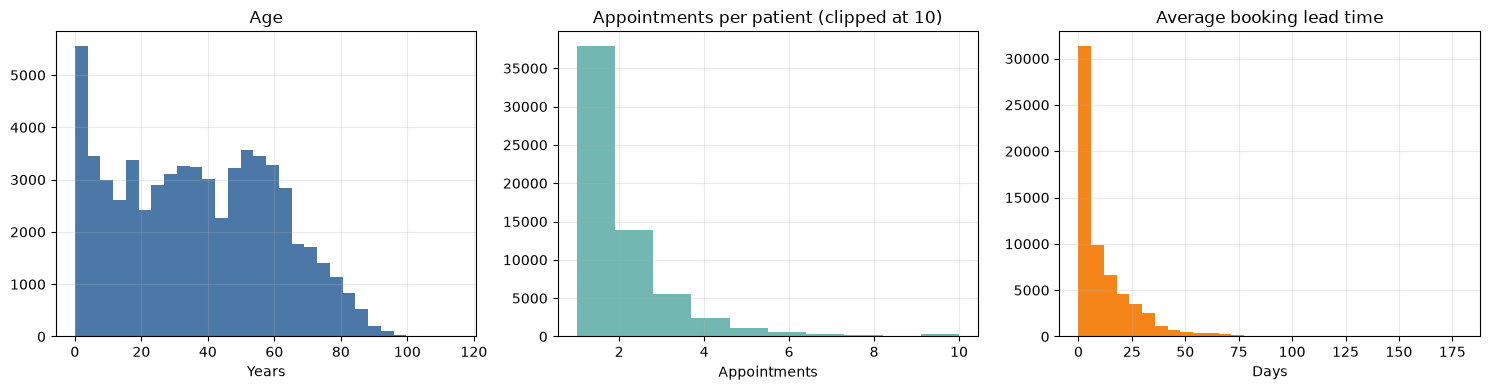

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(patients["age"], bins=30, color="#4c78a8")
axes[0].set_title("Age")
axes[0].set_xlabel("Years")

axes[1].hist(patients["appointments"].clip(upper=10), bins=10, color="#72b7b2")
axes[1].set_title("Appointments per patient (clipped at 10)")
axes[1].set_xlabel("Appointments")

axes[2].hist(patients["avg_lead_time"], bins=30, color="#f58518")
axes[2].set_title("Average booking lead time")
axes[2].set_xlabel("Days")

plt.tight_layout()
plt.show()
        

## 2. Choose the number of clusters

In [4]:
feature_columns = ["age", "appointments", "avg_lead_time", "chronic_conditions", "sms_rate"]
X = patients[feature_columns].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k_values = range(2, 9)
inertias = []
silhouettes = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(
        silhouette_score(X_scaled, model.labels_, sample_size=5000, random_state=42)
    )

cluster_scan = pd.DataFrame(
    {"k": list(k_values), "inertia": np.round(inertias, 1), "silhouette": np.round(silhouettes, 3)}
)
cluster_scan
        

,k,inertia,silhouette
0,2,242455.1,0.327
1,3,187277.8,0.332
2,4,164221.0,0.344
3,5,144560.5,0.335
4,6,128111.5,0.338
5,7,110571.1,0.301
6,8,99953.8,0.316


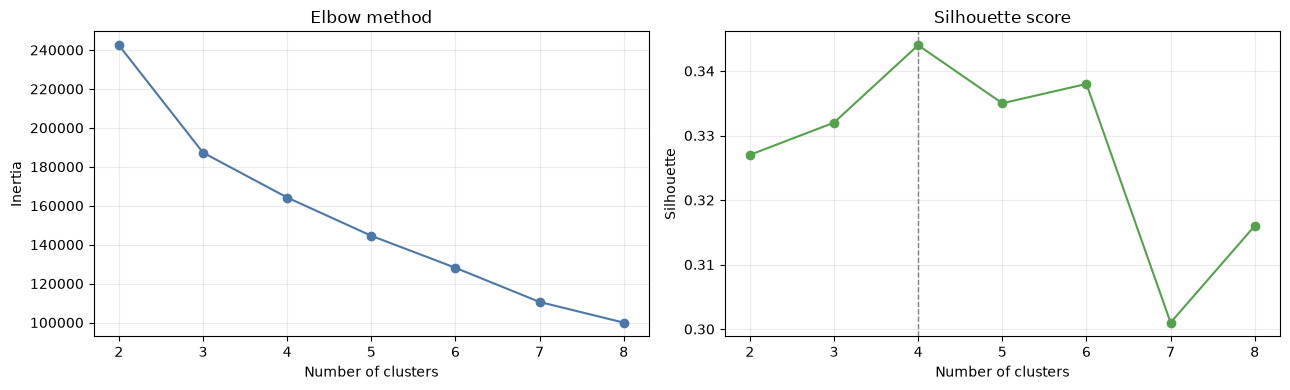

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(cluster_scan["k"], cluster_scan["inertia"], marker="o", color="#4c78a8")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(cluster_scan["k"], cluster_scan["silhouette"], marker="o", color="#54a24b")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette")
axes[1].axvline(4, linestyle="--", color="grey", linewidth=1)

plt.tight_layout()
plt.show()
        

The silhouette curve is relatively flat. We use **k = 4** because it gives a compact set of segments with clear operational interpretations (frequent attenders, older chronic patients, long-lead bookers and younger low-contact patients).
        

## 3. Fit the final K-Means model

In [6]:
segmentation_model = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=4, n_init=20, random_state=42)),
    ]
)
segmentation_model.fit(X)
patients["cluster"] = segmentation_model.predict(X)

final_kmeans = segmentation_model.named_steps["kmeans"]
final_silhouette = silhouette_score(
    segmentation_model.named_steps["scaler"].transform(X),
    patients["cluster"],
    sample_size=5000,
    random_state=42,
)
print(f"k = 4 | inertia = {final_kmeans.inertia_:,.1f} | silhouette = {final_silhouette:.3f}")
        

k = 4 | inertia = 164,221.0 | silhouette = 0.344


## 4. Profile and label the segments

In [7]:
profiles = (
    patients.groupby("cluster")[feature_columns + ["no_show_rate"]]
    .mean()
    .round(2)
)
profiles["patients"] = patients["cluster"].value_counts().sort_index()
profiles["share"] = (profiles["patients"] / len(patients)).round(3)

# Label clusters from their strongest operational characteristic.
labels = {}
remaining = set(profiles.index)

def assign_label(metric, label):
    cluster_id = profiles.loc[list(remaining), metric].idxmax()
    labels[int(cluster_id)] = label
    remaining.remove(cluster_id)

assign_label("appointments", "Frequent attenders")
assign_label("age", "Older chronic patients")
assign_label("avg_lead_time", "Long-lead bookers")
for cluster_id in remaining:
    labels[int(cluster_id)] = "Young low-contact patients"

profiles["segment"] = profiles.index.map(labels)
profiles.sort_values("patients", ascending=False)
        

,age,appointments,avg_lead_time,chronic_conditions,sms_rate,no_show_rate,patients,share,segment
cluster,,,,,,,,,
2,28.22,1.57,5.76,0.01,0.07,0.17,30890,0.496,Young low-contact patients
1,34.60,1.43,24.21,0.10,0.88,0.28,16783,0.269,Long-lead bookers
0,61.10,1.66,7.54,1.37,0.24,0.16,12268,0.197,Older chronic patients
3,36.07,7.41,7.69,0.21,0.31,0.22,2357,0.038,Frequent attenders


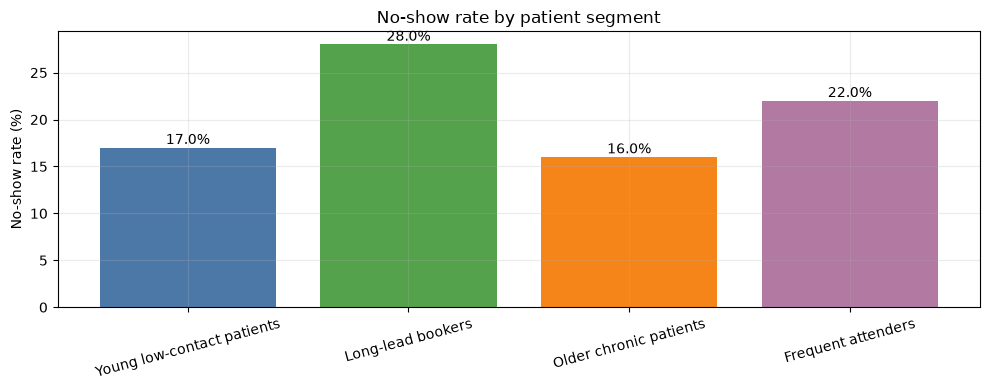

In [8]:
segment_descriptions = {
    "Frequent attenders": (
        "High-utilisation patients with many appointments. Prioritise care coordination, "
        "continuity of care and proactive outreach."
    ),
    "Older chronic patients": (
        "Older patients with more chronic conditions. Focus on chronic-care follow-up, "
        "transport support and accessible appointment times."
    ),
    "Long-lead bookers": (
        "Patients who book well in advance and receive many SMS reminders. Send confirmations "
        "closer to the visit and use waiting-list backfill."
    ),
    "Young low-contact patients": (
        "Younger, low-utilisation patients with little SMS contact. Use digital reminders, "
        "self-service rescheduling and first-appointment follow-up."
    ),
}

segment_order = profiles.sort_values("patients", ascending=False).index.tolist()
colors = {
    labels[cid]: color
    for cid, color in zip(segment_order, ["#4c78a8", "#54a24b", "#f58518", "#b279a2"])
}

fig, ax = plt.subplots(figsize=(10, 4))
plot_data = profiles.loc[segment_order]
ax.bar(
    [labels[int(cid)] for cid in segment_order],
    plot_data["no_show_rate"] * 100,
    color=[colors[labels[int(cid)]] for cid in segment_order],
)
ax.set_title("No-show rate by patient segment")
ax.set_ylabel("No-show rate (%)")
ax.tick_params(axis="x", rotation=15)
for i, (cid, row) in enumerate(plot_data.iterrows()):
    ax.text(i, row["no_show_rate"] * 100 + 0.4, f"{row['no_show_rate'] * 100:.1f}%", ha="center")
plt.tight_layout()
plt.show()
        

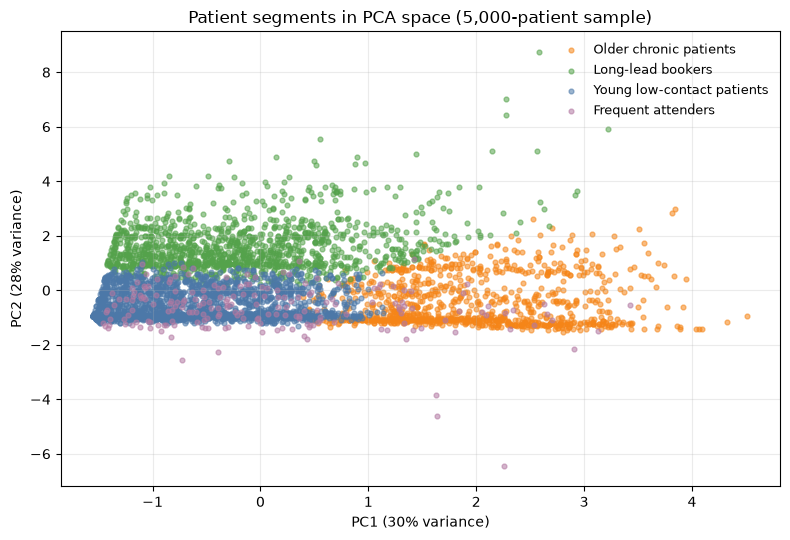

In [9]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(segmentation_model.named_steps["scaler"].transform(X))
plot_sample = patients.sample(n=min(5000, len(patients)), random_state=42)
plot_coords = coords[plot_sample.index]

fig, ax = plt.subplots(figsize=(8, 5.5))
for cluster_id in sorted(profiles.index):
    mask = patients.loc[plot_sample.index, "cluster"].to_numpy() == cluster_id
    ax.scatter(
        plot_coords[mask, 0],
        plot_coords[mask, 1],
        s=12,
        alpha=0.55,
        label=labels[int(cluster_id)],
        color=colors[labels[int(cluster_id)]],
    )
ax.set_title("Patient segments in PCA space (5,000-patient sample)")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()
        

## 5. Save the segmentation model and metadata

In [10]:
joblib.dump(segmentation_model, MODEL_DIR / "patient_kmeans.joblib")

cluster_profiles = {}
for cluster_id, row in profiles.iterrows():
    cluster_profiles[str(int(cluster_id))] = {
        "label": labels[int(cluster_id)],
        "patients": int(row["patients"]),
        "share": float(row["share"]),
        "age": float(row["age"]),
        "appointments": float(row["appointments"]),
        "avg_lead_time": float(row["avg_lead_time"]),
        "chronic_conditions": float(row["chronic_conditions"]),
        "sms_rate": float(row["sms_rate"]),
        "no_show_rate": float(row["no_show_rate"]),
    }

segments_meta = {
    "model": "KMeans",
    "k": 4,
    "trained_at": pd.Timestamp.now().isoformat(timespec="seconds"),
    "n_patients": int(len(patients)),
    "features": feature_columns,
    "inertia": float(final_kmeans.inertia_),
    "silhouette": float(final_silhouette),
    "cluster_profiles": cluster_profiles,
    "cluster_descriptions": segment_descriptions,
    "overall_no_show_rate": float(patients["no_show_rate"].mean()),
    "cluster_scan": cluster_scan.to_dict(orient="records"),
    "pca_explained_variance": [float(v) for v in pca.explained_variance_ratio_],
}

with open(MODEL_DIR / "segments_meta.json", "w", encoding="utf-8") as f:
    json.dump(segments_meta, f, indent=2)

print("Saved:")
print(" -", MODEL_DIR / "patient_kmeans.joblib")
print(" -", MODEL_DIR / "segments_meta.json")
        

Saved:
 - C:\Users\Lenovo\health_analytics\models\patient_kmeans.joblib
 - C:\Users\Lenovo\health_analytics\models\segments_meta.json


### Result

- Patients are grouped by utilisation and engagement, not by their no-show outcome.
- The segment profiles reveal meaningful differences in no-show rate, which the dashboard uses to recommend outreach strategies.
- **Artifacts:** `models/patient_kmeans.joblib`, `models/segments_meta.json`.
        